In [1]:
from catboost import CatBoostClassifier
from catboost import Pool
from sklearn.model_selection import GroupKFold, ParameterGrid
from sklearn.metrics import f1_score, classification_report, confusion_matrix

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

from scipy.interpolate import interp1d
import torch

In [2]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")
if device == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Using device: cuda
GPU: NVIDIA GeForce RTX 5060 Laptop GPU


In [3]:
seed = 42

In [4]:
df = pd.read_csv("Data/data_kern_ratios_04_11.csv")

In [5]:
elements = ['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe',
    'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo']

In [6]:
df[elements]

,Mg,Al,Si,P,S,K,Ca,Ti,Mn,Fe,Ni,Cu,Zn,Se,Rb,Sr,Zr,Mo
0,1.821148,7.515664,18.611483,0.299690,10.465318,0.942543,1.469765,0.000315,0.023969,5.472308,0.003111,0.005070,0.008353,0.000145,0.004428,0.017295,0.005169,0.006378
1,1.266357,7.461183,16.904798,0.000253,14.653735,0.883390,0.000620,0.140444,0.008495,6.964299,0.002921,0.006038,0.012220,0.000321,0.003050,0.009028,0.003092,0.007169
2,1.724880,7.150965,18.068731,0.000253,13.442425,0.930935,0.054942,0.000315,0.022970,5.942331,0.001074,0.005473,0.008705,0.000180,0.003570,0.018256,0.005030,0.006039
3,1.646439,8.260792,21.260196,0.000253,10.257598,1.235161,0.000620,0.184038,0.014205,4.126949,0.003727,0.005191,0.008845,0.000180,0.004764,0.011463,0.004061,0.005446
4,1.847176,7.757235,19.837340,0.000253,10.623499,1.059210,0.478515,0.000315,0.022656,5.052294,0.003111,0.007288,0.013555,0.000286,0.004397,0.016122,0.002446,0.006519
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3022,2.129802,4.410461,8.497462,1.992644,10.053492,0.514109,4.325427,0.000315,0.107449,13.178634,0.000979,0.001703,0.006033,0.000004,0.001672,0.029409,0.003277,0.000469
3023,1.863934,12.555305,24.545034,0.084607,1.785869,1.701369,0.058194,0.397704,0.020486,2.164767,0.000553,0.001703,0.008986,0.000004,0.005071,0.011373,0.008861,0.000469
3024,1.705032,12.769895,24.812063,0.000253,1.558093,1.863352,0.000620,0.397608,0.020115,2.041525,0.000790,0.001703,0.008634,0.000004,0.005346,0.011643,0.008630,0.000469
3025,1.680073,12.810209,25.421817,0.038680,1.082697,1.895027,0.000620,0.408698,0.014690,1.656151,0.000600,0.001703,0.008213,0.000004,0.005622,0.012064,0.009830,0.000469


**Разведочный анализ шага замеров (depth spacing)**

In [7]:
well_col = 'Well'
depth_col = 'Depth'

Всего проб: 3027, Скважин: 14

ОБЩАЯ СТАТИСТИКА ПО ШАГАМ (м)
count    3013.000000
mean        0.165144
std         0.424891
min         0.000000
1%          0.010000
5%          0.030000
25%         0.080000
50%         0.130000
75%         0.190000
95%         0.314000
99%         0.630000
max        19.000000
Name: step, dtype: float64

Порог аномалии (99-й процентиль): 0.630 м
Количество аномальных шагов: 30

Примеры аномальных шагов (топ-10):
Well   Depth  step
  A1 2750.70  1.21
  A1 2751.56  0.71
  A1 2753.24  1.15
  A2 2761.36  1.93
  A3 2737.35  1.70
  A3 2746.97  0.74
  A4 2764.35  6.22
  B1 2742.84  2.57
  B1 2746.82  1.08
  C1 2802.44  0.96


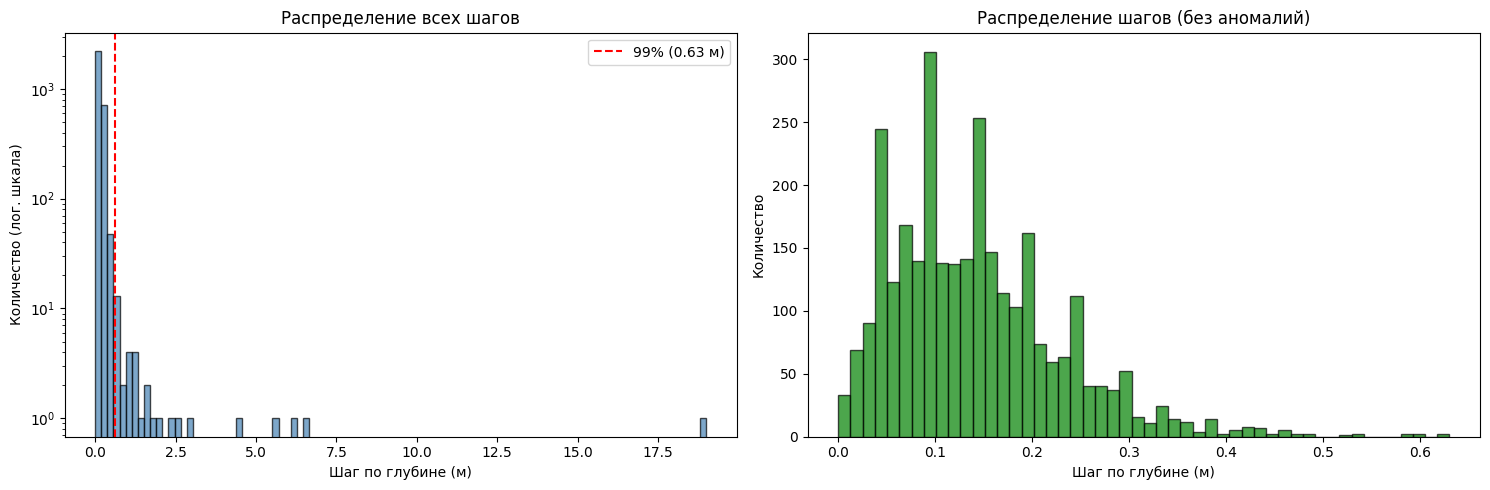


СРЕДНИЙ ШАГ ПО СКВАЖИНАМ
      count      mean  median    max
Well                                
C5      159  0.213082   0.090  19.00
E1      146  0.212192   0.160   5.55
B1      178  0.200393   0.170   2.57
C4      166  0.200000   0.185   1.81
C2      121  0.196198   0.170   1.59
A2      176  0.191477   0.180   1.93
C1      259  0.183436   0.140   6.47
A4      194  0.180103   0.130   6.22
D1      175  0.172000   0.160   1.30
A3      178  0.171124   0.150   1.70
C3      206  0.169563   0.150   0.90
C7      358  0.146592   0.100   4.42
C6      198  0.127576   0.100   2.34
A1      499  0.101663   0.080   1.21


In [8]:
print(f"Всего проб: {len(df)}, Скважин: {df[well_col].nunique()}")

# шаги (разницу глубин) внутри каждой скважины

df_sorted = df.sort_values([well_col, depth_col]).reset_index(drop=True)

# шаг: глубина текущей пробы минус глубина предыдущей
df_sorted['step'] = df_sorted.groupby(well_col)[depth_col].diff()

# только положительные шаги (внутри скважин)
steps = df_sorted['step'].dropna()

# Общая статистика по шагам
print("\nОБЩАЯ СТАТИСТИКА ПО ШАГАМ (м)")
print(steps.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]))

# Поиск аномалий (пропусков)
threshold = steps.quantile(0.99)
print(f"\nПорог аномалии (99-й процентиль): {threshold:.3f} м")

anomalies = df_sorted[df_sorted['step'] > threshold]
print(f"Количество аномальных шагов: {len(anomalies)}")
if len(anomalies) > 0:
    print("\nПримеры аномальных шагов (топ-10):")
    print(anomalies[[well_col, depth_col, 'step']].head(10).to_string(index=False))

# Визуализация распределения шагов
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Логарифмическая шкала
axes[0].hist(steps, bins=100, color='steelblue', edgecolor='black', alpha=0.7)
axes[0].set_yscale('log')
axes[0].set_xlabel('Шаг по глубине (м)')
axes[0].set_ylabel('Количество (лог. шкала)')
axes[0].set_title('Распределение всех шагов')
axes[0].axvline(threshold, color='red', linestyle='--', label=f'99% ({threshold:.2f} м)')
axes[0].legend()

# Детальный вид на "нормальные" шаги (без выбросов)
normal_steps = steps[steps <= threshold]
axes[1].hist(normal_steps, bins=50, color='green', edgecolor='black', alpha=0.7)
axes[1].set_xlabel('Шаг по глубине (м)')
axes[1].set_ylabel('Количество')
axes[1].set_title('Распределение шагов (без аномалий)')

plt.tight_layout()
plt.show()

# по скважинам (средний шаг)
print("\nСРЕДНИЙ ШАГ ПО СКВАЖИНАМ")
well_stats = df_sorted.groupby(well_col)['step'].agg(['count', 'mean', 'median', 'max'])
print(well_stats.sort_values('mean', ascending=False))

**Интерполяция с разрывами**

In [9]:
# Загрузка
df = pd.read_csv("Data/data_kern_ratios_04_11.csv")

elements = ['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe', 
            'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo']

# Создание единой сетки глубин для скважины (с разрывами)
def create_regular_grid(df_well, step=0.05, max_gap=0.4):
    depths = df_well['Depth'].values
    
    # Находим индексы, где начинаются разрывы (шаг > max_gap)
    gaps = np.where(np.diff(depths) > max_gap)[0] + 1
    # Разбиваем на интервалы
    intervals = np.split(np.arange(len(depths)), gaps)
    
    regular_depths_list = []
    
    for i, interval in enumerate(intervals):
        if len(interval) < 2:
            continue
        
        d_int = depths[interval]
        
        # Создаем регулярную сетку для этого интервала
        reg_d = np.round(np.arange(d_int.min(), d_int.max(), step), 3)
        regular_depths_list.append(reg_d)
        
        # Добавляем "маркер разрыва" 
        if i < len(intervals) - 1:
            regular_depths_list.append(np.array([d_int.max() + step]))
    
    return np.concatenate(regular_depths_list)

# Интерполяция одного элемента на готовую сетку
def interpolate_element_to_grid(df_well, element, reg_depths, max_gap=0.4):
    depths = df_well['Depth'].values
    values = df_well[element].values
    
    # Для каждой регулярной глубины находим, в какой интервал она попадает
    result = np.full(len(reg_depths), np.nan)
    
    # Находим индексы разрывов в исходных данных
    gaps = np.where(np.diff(depths) > max_gap)[0] + 1
    intervals = np.split(np.arange(len(depths)), gaps)
    
    for interval in intervals:
        if len(interval) < 2:
            continue
        
        d_int = depths[interval]
        v_int = values[interval]
        
        # Маска для точек регулярной сетки, попадающих в этот интервал
        mask = (reg_depths >= d_int.min()) & (reg_depths <= d_int.max())
        
        if np.any(mask):
            # Интерполируем только на эти точки
            result[mask] = np.interp(reg_depths[mask], d_int, v_int)
    
    return result

# Интерполяция стратиграфии (nearest neighbor) на готовую сетку
def interpolate_strat_to_grid(df_well, reg_depths, max_gap=0.4):
    depths = df_well['Depth'].values
    strat = df_well['Strat'].values.astype(int)
    
    strat_interp = interp1d(
        depths, strat, kind='nearest', 
        bounds_error=False, fill_value='extrapolate'
    )
    
    strat_values = strat_interp(reg_depths).astype(float)
    
    # Обнуляем значения в зонах разрывов
    for i, d in enumerate(reg_depths):
        # Проверяем, не попадает ли точка в разрыв
        left_idx = np.searchsorted(depths, d, side='right') - 1
        right_idx = left_idx + 1
        
        if left_idx >= 0 and right_idx < len(depths):
            # Если точка находится между двумя пробами из РАЗНЫХ интервалов
            if (depths[right_idx] - depths[left_idx]) > max_gap:
                strat_values[i] = np.nan
    
    return strat_values

# Сборка датасета
all_wells_data = []

for well in df['Well'].unique():
    df_well = df[df['Well'] == well].sort_values('Depth').reset_index(drop=True)
    
    # Создаем единую сетку глубин для скважины
    reg_d = create_regular_grid(df_well, step=0.05, max_gap=0.4)
    
    # Интерполируем стратиграфию на эту сетку
    strat_values = interpolate_strat_to_grid(df_well, reg_d, max_gap=0.4)
    
    # Создаем DataFrame
    df_well_interp = pd.DataFrame({
        'Well': well,
        'Depth': reg_d,
        'Strat': strat_values
    })
    
    # Интерполируем каждый элемент на эту же сетку
    for el in elements:
        df_well_interp[el] = interpolate_element_to_grid(df_well, el, reg_d, max_gap=0.4)
    
    all_wells_data.append(df_well_interp)
    
    # Проверка: сколько строк с NaN по всем элементам (должно быть ~0, кроме маркеров разрывов)
    n_nan = df_well_interp[elements].isna().all(axis=1).sum()
    print(f"Скважина {well}: {len(df_well_interp)} проб (из {len(df_well)} исходных), "
          f"строк с полным NaN: {n_nan}")

# Объединяем
df_interpolated = pd.concat(all_wells_data, ignore_index=True)

# Проверка
print(f"\nВсего проб: {len(df_interpolated)}")
print(f"Скважин: {df_interpolated['Well'].nunique()}")
print(f"Элементов: {len(elements)}")

# Проверка "фантомных" строк
all_nan_rows = df_interpolated[df_interpolated[elements].isna().all(axis=1)]
print(f"\nВсего 'фантомных' строк (все элементы NaN): {len(all_nan_rows)}")
print("Примеры 'фантомных' строк (должны быть только маркерами разрывов):")
print(all_nan_rows[['Well', 'Depth', 'Strat']].head(10))

# Сохранение
df_interpolated.to_csv("Data/data_kern_interpolated_0-05m_gap04.csv", index=False)
print("\nСохранено в Data/data_kern_interpolated_0-05m_gap04.csv")

Скважина C3: 660 проб (из 207 исходных), строк с полным NaN: 3
Скважина A1: 930 проб (из 500 исходных), строк с полным NaN: 4
Скважина A2: 605 проб (из 177 исходных), строк с полным NaN: 4
Скважина A3: 557 проб (из 179 исходных), строк с полным NaN: 5
Скважина A4: 547 проб (из 195 исходных), строк с полным NaN: 6
Скважина E1: 487 проб (из 147 исходных), строк с полным NaN: 4
Скважина C1: 709 проб (из 260 исходных), строк с полным NaN: 9
Скважина C2: 438 проб (из 122 исходных), строк с полным NaN: 2
Скважина D1: 560 проб (из 176 исходных), строк с полным NaN: 3
Скважина B1: 598 проб (из 179 исходных), строк с полным NaN: 7
Скважина C4: 578 проб (из 167 исходных), строк с полным NaN: 5
Скважина C5: 299 проб (из 160 исходных), строк с полным NaN: 1
Скважина C6: 441 проб (из 199 исходных), строк с полным NaN: 3
Скважина C7: 774 проб (из 359 исходных), строк с полным NaN: 13

Всего проб: 8183
Скважин: 14
Элементов: 18

Всего 'фантомных' строк (все элементы NaN): 69
Примеры 'фантомных' строк

In [10]:
# Сравнение распределения до и после
print("До интерполяции:")
print(df['Strat'].value_counts().sort_index())
print("\nПосле интерполяции:")
print(df_interpolated['Strat'].value_counts().sort_index())

До интерполяции:
Strat
0     448
1     156
2     182
3     267
4     232
5     133
6     131
7     194
8     365
9     469
10    267
11    183
Name: count, dtype: int64

После интерполяции:
Strat
0.0     1268
1.0      454
2.0      492
3.0      731
4.0      505
5.0      316
6.0      347
7.0      446
8.0      952
9.0     1252
10.0     796
11.0     554
Name: count, dtype: int64


**Создание моделей синтетического шлама**

In [11]:
def create_synthetic_slag(df, elements, window_m, noise_level=0, seed=42):
    """
    Создаёт синтетический шлам из керна.
    Свертка применяется ТОЛЬКО внутри непрерывных интервалов (без NaN).
    
    Параметры:
    ----------
    df : pd.DataFrame
        Датасет с керном. Колонки: Well, Depth, Strat, elements
        Может содержать строки-маркеры разрывов (все элементы NaN).
    elements : list
        Список элементов (18 штук)
    window_m : float
        Ширина окна перемешивания в метрах
    noise_level : float
        Уровень шума: 0 (без шума), 0.1, 0.3, 0.5
        σ = noise_level × std(element)
    seed : int
        Random seed для воспроизводимости
    
    Возвращает:
    -----------
    df_slag : pd.DataFrame
        Колонки: Well, Depth, Strat, {el}_kern, {el}_clean, {el}_slag
        Строки-маркеры разрывов сохранены (все элементы NaN).
    """
    np.random.seed(seed)
    
    sigma_m = window_m / 3
    df_slag_list = []
    
    for well in df['Well'].unique():
        df_well = df[df['Well'] == well].sort_values('Depth').reset_index(drop=True)
        
        # Находим строки-маркеры разрывов (все элементы NaN)
        is_gap = df_well[elements].isna().all(axis=1)
        
        # Разбиваем на непрерывные интервалы
        # (индексы строк, где нет NaN)
        intervals = []
        current_interval = []
        
        for i in range(len(df_well)):
            if is_gap.iloc[i]:
                # Это разрыв — закрываем текущий интервал
                if len(current_interval) > 0:
                    intervals.append(current_interval)
                    current_interval = []
            else:
                current_interval.append(i)
        
        # Закрываем последний интервал
        if len(current_interval) > 0:
            intervals.append(current_interval)
        
        # Создаем DataFrame для результата (копия исходного)
        df_well_slag = df_well[['Well', 'Depth', 'Strat']].copy()
        
        # Инициализируем колонки для элементов (NaN по умолчанию)
        for el in elements:
            df_well_slag[f'{el}_kern'] = np.nan
            df_well_slag[f'{el}_clean'] = np.nan
            df_well_slag[f'{el}_slag'] = np.nan
        
        # Обрабатываем каждый непрерывный интервал отдельно
        for interval_indices in intervals:
            if len(interval_indices) < 2:
                # Слишком короткий интервал, просто копируем данные без свертки
                for el in elements:
                    df_well_slag.loc[interval_indices, f'{el}_kern'] = df_well.loc[interval_indices, el].values
                    df_well_slag.loc[interval_indices, f'{el}_clean'] = df_well.loc[interval_indices, el].values
                    df_well_slag.loc[interval_indices, f'{el}_slag'] = df_well.loc[interval_indices, el].values
                continue
            
            # Данные для этого интервала
            df_interval = df_well.iloc[interval_indices].reset_index(drop=True)
            depths = df_interval['Depth'].values
            n = len(depths)
            
            # std по этому интервалу (для шума)
            std_per_el = df_interval[elements].std()
            
            for el in elements:
                values = df_interval[el].values
                slag_clean = np.zeros(n)
                
                for j in range(n):
                    d_center = depths[j]
                    mask = (depths >= d_center - window_m) & (depths <= d_center)
                    d_window = depths[mask]
                    v_window = values[mask]
                    
                    distances = d_center - d_window
                    weights = np.exp(-0.5 * (distances / sigma_m) ** 2)
                    weights = weights / weights.sum()
                    
                    slag_clean[j] = np.sum(v_window * weights)
                
                # Шум пропорционален std ЭТОГО интервала
                if noise_level > 0:
                    sigma_noise = noise_level * std_per_el[el]
                    noise = np.random.normal(0, sigma_noise, size=n)
                    slag_noisy = slag_clean + noise
                else:
                    slag_noisy = slag_clean.copy()
                
                # Запись в общий DataFrame
                df_well_slag.loc[interval_indices, f'{el}_kern'] = values
                df_well_slag.loc[interval_indices, f'{el}_clean'] = slag_clean
                df_well_slag.loc[interval_indices, f'{el}_slag'] = slag_noisy
        
        df_slag_list.append(df_well_slag)
    
    df_slag = pd.concat(df_slag_list, ignore_index=True)
    return df_slag

In [12]:
# Проверка
print(f"Строк: {len(df_interpolated)}")
print(f"Скважин: {df_interpolated['Well'].nunique()}")
print(f"Маркеров разрывов: {df_interpolated[elements].isna().all(axis=1).sum()}")

Строк: 8183
Скважин: 14
Маркеров разрывов: 69


In [13]:
# Создание синтетического шлама
windows = [0.5, 1.0, 2.0, 3.0]
noise_levels = [0.1, 0.3, 0.5]

for window_m in windows:
    # Без шума
    df_slag = create_synthetic_slag(df_interpolated, elements, window_m, noise_level=0)
    df_slag.to_csv(f'Result/Synthetic_slag_06_11/synthetic_slag_w{window_m}_no_noise.csv', index=False)
    
    # С шумом
    for level in noise_levels:
        df_slag = create_synthetic_slag(df_interpolated, elements, window_m, noise_level=level)
        df_slag.to_csv(f'Result/Synthetic_slag_06_11/synthetic_slag_w{window_m}_s{level}.csv', index=False)

**Проверка**

In [14]:
# Количество строк должно совпадать с исходным датасетом
print(f"Исходных строк: {len(df_interpolated)}")
print(f"Строк в шламе: {len(df_slag)}")

# Маркеры разрывов должны быть NaN во всех колонках
gap_rows = df_slag[df_slag[elements[0] + '_kern'].isna()]
print(f"Маркеров разрывов: {len(gap_rows)}")

# В непрерывных интервалах не должно быть NaN
non_gap = df_slag[~df_slag[elements[0] + '_kern'].isna()]
print(f"Строк с данными: {len(non_gap)}")
print(f"NaN в _slag: {non_gap[[el + '_slag' for el in elements]].isna().sum().sum()}")

# Проверка шлам должен быть сглаженным керном
# (корреляция между _kern и _clean должна быть высокой)
from scipy.stats import pearsonr
for el in elements[:10]:  
    mask = ~df_slag[f'{el}_kern'].isna()
    corr, _ = pearsonr(df_slag.loc[mask, f'{el}_kern'], df_slag.loc[mask, f'{el}_clean'])
    print(f"{el}: корреляция kern vs clean = {corr:.3f}")

Исходных строк: 8183
Строк в шламе: 8183
Маркеров разрывов: 69
Строк с данными: 8114
NaN в _slag: 0
Mg: корреляция kern vs clean = 0.454
Al: корреляция kern vs clean = 0.852
Si: корреляция kern vs clean = 0.745
P: корреляция kern vs clean = 0.415
S: корреляция kern vs clean = 0.775
K: корреляция kern vs clean = 0.852
Ca: корреляция kern vs clean = 0.601
Ti: корреляция kern vs clean = 0.791
Mn: корреляция kern vs clean = 0.384
Fe: корреляция kern vs clean = 0.774


**NBD**

In [15]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
import time
import os
import joblib
import json

# Проверка GPU
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")
if device == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# Создаем папки
os.makedirs('Result/NBD_cleaned', exist_ok=True)
os.makedirs('Result/NBD_models', exist_ok=True)


elements = ['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe',
            'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo']

df_kern = pd.read_csv("Data/data_kern_interpolated_0-05m_gap04.csv")
print(f"Керн: {len(df_kern)} строк, {df_kern['Well'].nunique()} скважин")

# РАЗБИЕНИЕ ПО СКВАЖИНАМ
train_wells = ['A1', 'A3', 'A4', 'B1', 'C1', 'C4', 'C5', 'C6', 'D1']
val_wells = ['A2', 'E1']
test_wells = ['C2', 'C3', 'C7']

# FIT SCALERS (на train-скважинах)
def fit_scalers(df_kern, elements, train_wells):
    """Обучает StandardScaler для каждого элемента на train-скважинах."""
    scalers = {}
    df_train = df_kern[df_kern['Well'].isin(train_wells)]
    
    for el in elements:
        values = df_train[el].dropna().values.reshape(-1, 1)
        scaler = StandardScaler()
        scaler.fit(values)
        scalers[el] = scaler
    
    return scalers

print("\nFit scalers на train")
scalers = fit_scalers(df_kern, elements, train_wells)
joblib.dump(scalers, 'Result/NBD_models/scalers.pkl')
print("Scalers сохранены в Result/NBD_models/scalers.pkl")

# ПОДГОТОВКА ДАННЫХ (с нормализацией)
def prepare_nbd_data(df_kern, df_slag, elements, train_wells, val_wells, test_wells, scalers):
    """Готовит данные для NBD с нормализацией."""
    def get_intervals(wells, df_kern, df_slag):
        intervals = []
        for well in wells:
            df_k = df_kern[df_kern['Well'] == well].sort_values('Depth').reset_index(drop=True)
            df_s = df_slag[df_slag['Well'] == well].sort_values('Depth').reset_index(drop=True)
            
            is_gap = df_k[elements].isna().all(axis=1)
            
            current_X, current_y = [], []
            for i in range(len(df_k)):
                if is_gap.iloc[i]:
                    if len(current_X) > 10:
                        intervals.append((np.array(current_X), np.array(current_y)))
                    current_X, current_y = [], []
                else:
                    # Нормализуем шлам
                    X_row = []
                    for el in elements:
                        val = df_s.loc[i, f'{el}_slag']
                        val_norm = scalers[el].transform([[val]])[0, 0]
                        X_row.append(val_norm)
                    
                    # Нормализуем керн
                    y_row = []
                    for el in elements:
                        val = df_k.loc[i, el]
                        val_norm = scalers[el].transform([[val]])[0, 0]
                        y_row.append(val_norm)
                    
                    current_X.append(X_row)
                    current_y.append(y_row)
            
            if len(current_X) > 10:
                intervals.append((np.array(current_X), np.array(current_y)))
        
        return intervals
    
    train_intervals = get_intervals(train_wells, df_kern, df_slag)
    val_intervals = get_intervals(val_wells, df_kern, df_slag)
    test_intervals = get_intervals(test_wells, df_kern, df_slag)
    
    return train_intervals, val_intervals, test_intervals

# DATASET И DATALOADER
class NBDDataset(Dataset):
    def __init__(self, intervals):
        self.intervals = intervals
    
    def __len__(self):
        return len(self.intervals)
    
    def __getitem__(self, idx):
        X_slag, y_kern = self.intervals[idx]
        X_slag = torch.tensor(X_slag.T, dtype=torch.float32)
        y_kern = torch.tensor(y_kern.T, dtype=torch.float32)
        return X_slag, y_kern

def collate_fn(batch):
    Xs, ys = zip(*batch)
    max_len = max(x.shape[1] for x in Xs)
    
    X_padded = torch.zeros(len(Xs), Xs[0].shape[0], max_len)
    y_padded = torch.zeros(len(ys), ys[0].shape[0], max_len)
    
    for i, (x, y) in enumerate(zip(Xs, ys)):
        X_padded[i, :, :x.shape[1]] = x
        y_padded[i, :, :y.shape[1]] = y
    
    return X_padded, y_padded

# АРХИТЕКТУРА NBD
class NBD(nn.Module):
    def __init__(self, n_elements=18, n_filters=64, n_blocks=4, kernel_size=7):
        super().__init__()
        
        self.encoder = nn.Sequential(
            nn.Conv1d(n_elements, n_filters, kernel_size, padding='same'),
            nn.ReLU(),
            nn.Conv1d(n_filters, n_filters, kernel_size, padding='same'),
            nn.ReLU(),
        )
        
        self.res_blocks = nn.ModuleList([
            nn.Sequential(
                nn.Conv1d(n_filters, n_filters, kernel_size, padding='same'),
                nn.ReLU(),
                nn.Conv1d(n_filters, n_filters, kernel_size, padding='same'),
            )
            for _ in range(n_blocks)
        ])
        
        self.decoder = nn.Sequential(
            nn.Conv1d(n_filters, n_filters, kernel_size, padding='same'),
            nn.ReLU(),
            nn.Conv1d(n_filters, n_elements, kernel_size, padding='same'),
        )
    
    def forward(self, x):
        h = self.encoder(x)
        for block in self.res_blocks:
            h = h + block(h)
        return self.decoder(h)

# ФУНКЦИЯ ПОТЕРЬ
def nbd_loss(y_pred, y_kern):
    return nn.MSELoss()(y_pred, y_kern)

# ОБУЧЕНИЕ
def train_nbd(model, train_loader, val_loader, n_epochs=50, lr=1e-3, device='cuda', save_path='best_nbd.pth'):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5, factor=0.5)
    
    best_val_loss = float('inf')
    history = {'train': [], 'val': []}
    
    for epoch in range(n_epochs):
        # Train
        model.train()
        train_loss = 0
        for X_slag, y_kern in train_loader:
            X_slag, y_kern = X_slag.to(device), y_kern.to(device)
            optimizer.zero_grad()
            y_pred = model(X_slag)
            loss = nbd_loss(y_pred, y_kern)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()
        train_loss /= len(train_loader)
        
        # Val
        model.eval()
        val_loss = 0
        with torch.no_grad():
            for X_slag, y_kern in val_loader:
                X_slag, y_kern = X_slag.to(device), y_kern.to(device)
                y_pred = model(X_slag)
                val_loss += nbd_loss(y_pred, y_kern).item()
        val_loss /= len(val_loader)
        
        scheduler.step(val_loss)
        history['train'].append(train_loss)
        history['val'].append(val_loss)
        
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), save_path)
    
    # Загружаем лучшую модель
    model.load_state_dict(torch.load(save_path))
    return model, history

# ОЦЕНКА (с денормализацией)
def evaluate_nbd(model, test_loader, elements, scalers, device='cuda'):
    """Оценивает NBD: MSE, корреляция (в исходных единицах)."""
    model.eval()
    
    mse_list = []
    corr_per_el = {el: [] for el in elements}
    
    with torch.no_grad():
        for X_slag, y_kern in test_loader:
            X_slag, y_kern = X_slag.to(device), y_kern.to(device)
            y_pred = model(X_slag)
            
            preds_np = y_pred.cpu().numpy()
            trues_np = y_kern.cpu().numpy()
            
            # Денормализация
            for i, el in enumerate(elements):
                preds_np[:, i, :] = preds_np[:, i, :] * scalers[el].scale_[0] + scalers[el].mean_[0]
                trues_np[:, i, :] = trues_np[:, i, :] * scalers[el].scale_[0] + scalers[el].mean_[0]
            
            # MSE
            mse = np.mean((preds_np - trues_np) ** 2)
            mse_list.append(mse)
            
            # Корреляция
            for i, el in enumerate(elements):
                pred_el = preds_np[:, i, :].flatten()
                true_el = trues_np[:, i, :].flatten()
                
                if np.std(pred_el) > 1e-8 and np.std(true_el) > 1e-8:
                    corr = np.corrcoef(pred_el, true_el)[0, 1]
                    corr_per_el[el].append(corr)
    
    mean_mse = np.mean(mse_list)
    corr_dict = {
        el: np.mean(corr_per_el[el]) if len(corr_per_el[el]) > 0 else np.nan
        for el in elements
    }
    
    return mean_mse, corr_dict

# СОХРАНЕНИЕ NBD-ВОССТАНОВЛЕННОГО СИГНАЛА
def save_nbd_output(model_nbd, df_kern, df_slag, elements, scalers, output_path, device='cuda'):
    """Применяет NBD ко всем данным и сохраняет в CSV."""
    model_nbd.eval()
    result_rows = []
    
    for well in df_kern['Well'].unique():
        df_k = df_kern[df_kern['Well'] == well].sort_values('Depth').reset_index(drop=True)
        df_s = df_slag[df_slag['Well'] == well].sort_values('Depth').reset_index(drop=True)
        
        is_gap = df_k[elements].isna().all(axis=1)
        
        current_X = []
        current_indices = []
        
        def process_interval():
            if len(current_X) == 0:
                return
            X_tensor = torch.tensor(np.array(current_X).T, dtype=torch.float32).unsqueeze(0).to(device)
            with torch.no_grad():
                y_pred = model_nbd(X_tensor).cpu().numpy()[0].T
            
            # Денормализация
            for j, el in enumerate(elements):
                y_pred[:, j] = y_pred[:, j] * scalers[el].scale_[0] + scalers[el].mean_[0]
            
            for k, idx in enumerate(current_indices):
                row = {
                    'Well': well,
                    'Depth': df_k.loc[idx, 'Depth'],
                    'Strat': df_k.loc[idx, 'Strat'],
                }
                for j, el in enumerate(elements):
                    row[f'{el}_kern'] = df_k.loc[idx, el]
                    row[f'{el}_slag'] = df_s.loc[idx, f'{el}_slag']
                    row[f'{el}_nbd'] = y_pred[k, j]
                result_rows.append(row)
        
        for i in range(len(df_k)):
            if is_gap.iloc[i]:
                process_interval()
                current_X = []
                current_indices = []
            else:
                X_row = []
                for el in elements:
                    val = df_s.loc[i, f'{el}_slag']
                    val_norm = scalers[el].transform([[val]])[0, 0]
                    X_row.append(val_norm)
                current_X.append(X_row)
                current_indices.append(i)
        
        process_interval()
    
    df_result = pd.DataFrame(result_rows)
    df_result.to_csv(output_path, index=False)
    print(f"Сохранено: {output_path} ({len(df_result)} строк)")
    return df_result

# ОСНОВНОЙ ЦИКЛ ПО СЦЕНАРИЯМ
windows = [0.5, 1.0, 2.0, 3.0]
noise_levels = [0.0, 0.1, 0.3, 0.5]

results = []

for window_m in windows:
    for noise_level in noise_levels:
        print(f"Сценарий: w={window_m} м, σ={noise_level}")
        
        # Загрузка шлама
        if noise_level == 0.0:
            df_slag = pd.read_csv(f"Result/Synthetic_slag_06_11/synthetic_slag_w{window_m}_no_noise.csv")
            suffix = 'no_noise'
        else:
            df_slag = pd.read_csv(f"Result/Synthetic_slag_06_11/synthetic_slag_w{window_m}_s{noise_level}.csv")
            suffix = f's{noise_level}'
        
        # Подготовка данных
        train_int, val_int, test_int = prepare_nbd_data(
            df_kern, df_slag, elements, train_wells, val_wells, test_wells, scalers
        )
        
        # DataLoader
        train_loader = DataLoader(NBDDataset(train_int), batch_size=8, shuffle=True, collate_fn=collate_fn)
        val_loader = DataLoader(NBDDataset(val_int), batch_size=8, shuffle=False, collate_fn=collate_fn)
        test_loader = DataLoader(NBDDataset(test_int), batch_size=8, shuffle=False, collate_fn=collate_fn)
        
        # Модель
        model = NBD(n_elements=18, n_filters=64, n_blocks=4, kernel_size=7).to(device)
        
        # Обучение
        save_path = f'Result/NBD_models/best_nbd_w{window_m}_{suffix}.pth'
        model, history = train_nbd(
            model, train_loader, val_loader,
            n_epochs=50, lr=1e-3, device=device,
            save_path=save_path
        )
        
        # Оценка
        mse, corr_dict = evaluate_nbd(model, test_loader, elements, scalers, device=device)
        
        # Сохранение метрик
        for el in elements:
            results.append({
                'window': window_m,
                'noise': noise_level,
                'element': el,
                'mse': mse,
                'corr_nbd': corr_dict[el]
            })
        
        # Сохранение NBD-восстановленного сигнала
        output_path = f'Result/NBD_cleaned/synthetic_slag_w{window_m}_{suffix}_nbd.csv'
        save_nbd_output(model, df_kern, df_slag, elements, scalers, output_path, device=device)

# СОХРАНЕНИЕ РЕЗУЛЬТАТОВ
df_results = pd.DataFrame(results)
df_results.to_csv('Result/NBD_results_all_scenarios_normalized.csv', index=False)
print("\nРезультаты сохранены в Result/NBD_results_all_scenarios_normalized.csv")

Using device: cuda
GPU: NVIDIA GeForce RTX 5060 Laptop GPU
Керн: 8183 строк, 14 скважин

Fit scalers на train
Scalers сохранены в Result/NBD_models/scalers.pkl
Сценарий: w=0.5 м, σ=0.0
Сохранено: Result/NBD_cleaned/synthetic_slag_w0.5_no_noise_nbd.csv (8114 строк)
Сценарий: w=0.5 м, σ=0.1
Сохранено: Result/NBD_cleaned/synthetic_slag_w0.5_s0.1_nbd.csv (8114 строк)
Сценарий: w=0.5 м, σ=0.3
Сохранено: Result/NBD_cleaned/synthetic_slag_w0.5_s0.3_nbd.csv (8114 строк)
Сценарий: w=0.5 м, σ=0.5
Сохранено: Result/NBD_cleaned/synthetic_slag_w0.5_s0.5_nbd.csv (8114 строк)
Сценарий: w=1.0 м, σ=0.0
Сохранено: Result/NBD_cleaned/synthetic_slag_w1.0_no_noise_nbd.csv (8114 строк)
Сценарий: w=1.0 м, σ=0.1
Сохранено: Result/NBD_cleaned/synthetic_slag_w1.0_s0.1_nbd.csv (8114 строк)
Сценарий: w=1.0 м, σ=0.3
Сохранено: Result/NBD_cleaned/synthetic_slag_w1.0_s0.3_nbd.csv (8114 строк)
Сценарий: w=1.0 м, σ=0.5
Сохранено: Result/NBD_cleaned/synthetic_slag_w1.0_s0.5_nbd.csv (8114 строк)
Сценарий: w=2.0 м, σ=0.0

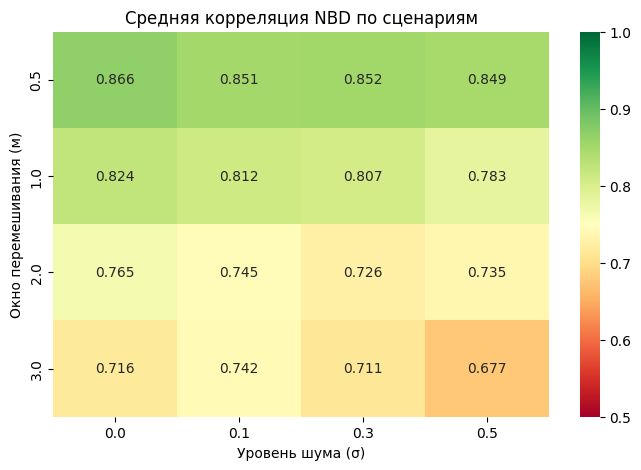

In [16]:
import seaborn as sns

# Pivot table: window × noise, средняя корреляция по элементам
pivot = df_results.groupby(['window', 'noise'])['corr_nbd'].mean().reset_index()
pivot_table = pivot.pivot(index='window', columns='noise', values='corr_nbd')

plt.figure(figsize=(8, 5))
sns.heatmap(pivot_table, annot=True, fmt='.3f', cmap='RdYlGn', vmin=0.5, vmax=1.0)
plt.title('Средняя корреляция NBD по сценариям')
plt.xlabel('Уровень шума (σ)')
plt.ylabel('Окно перемешивания (м)')
plt.show()

Скважина C3: 657 проб


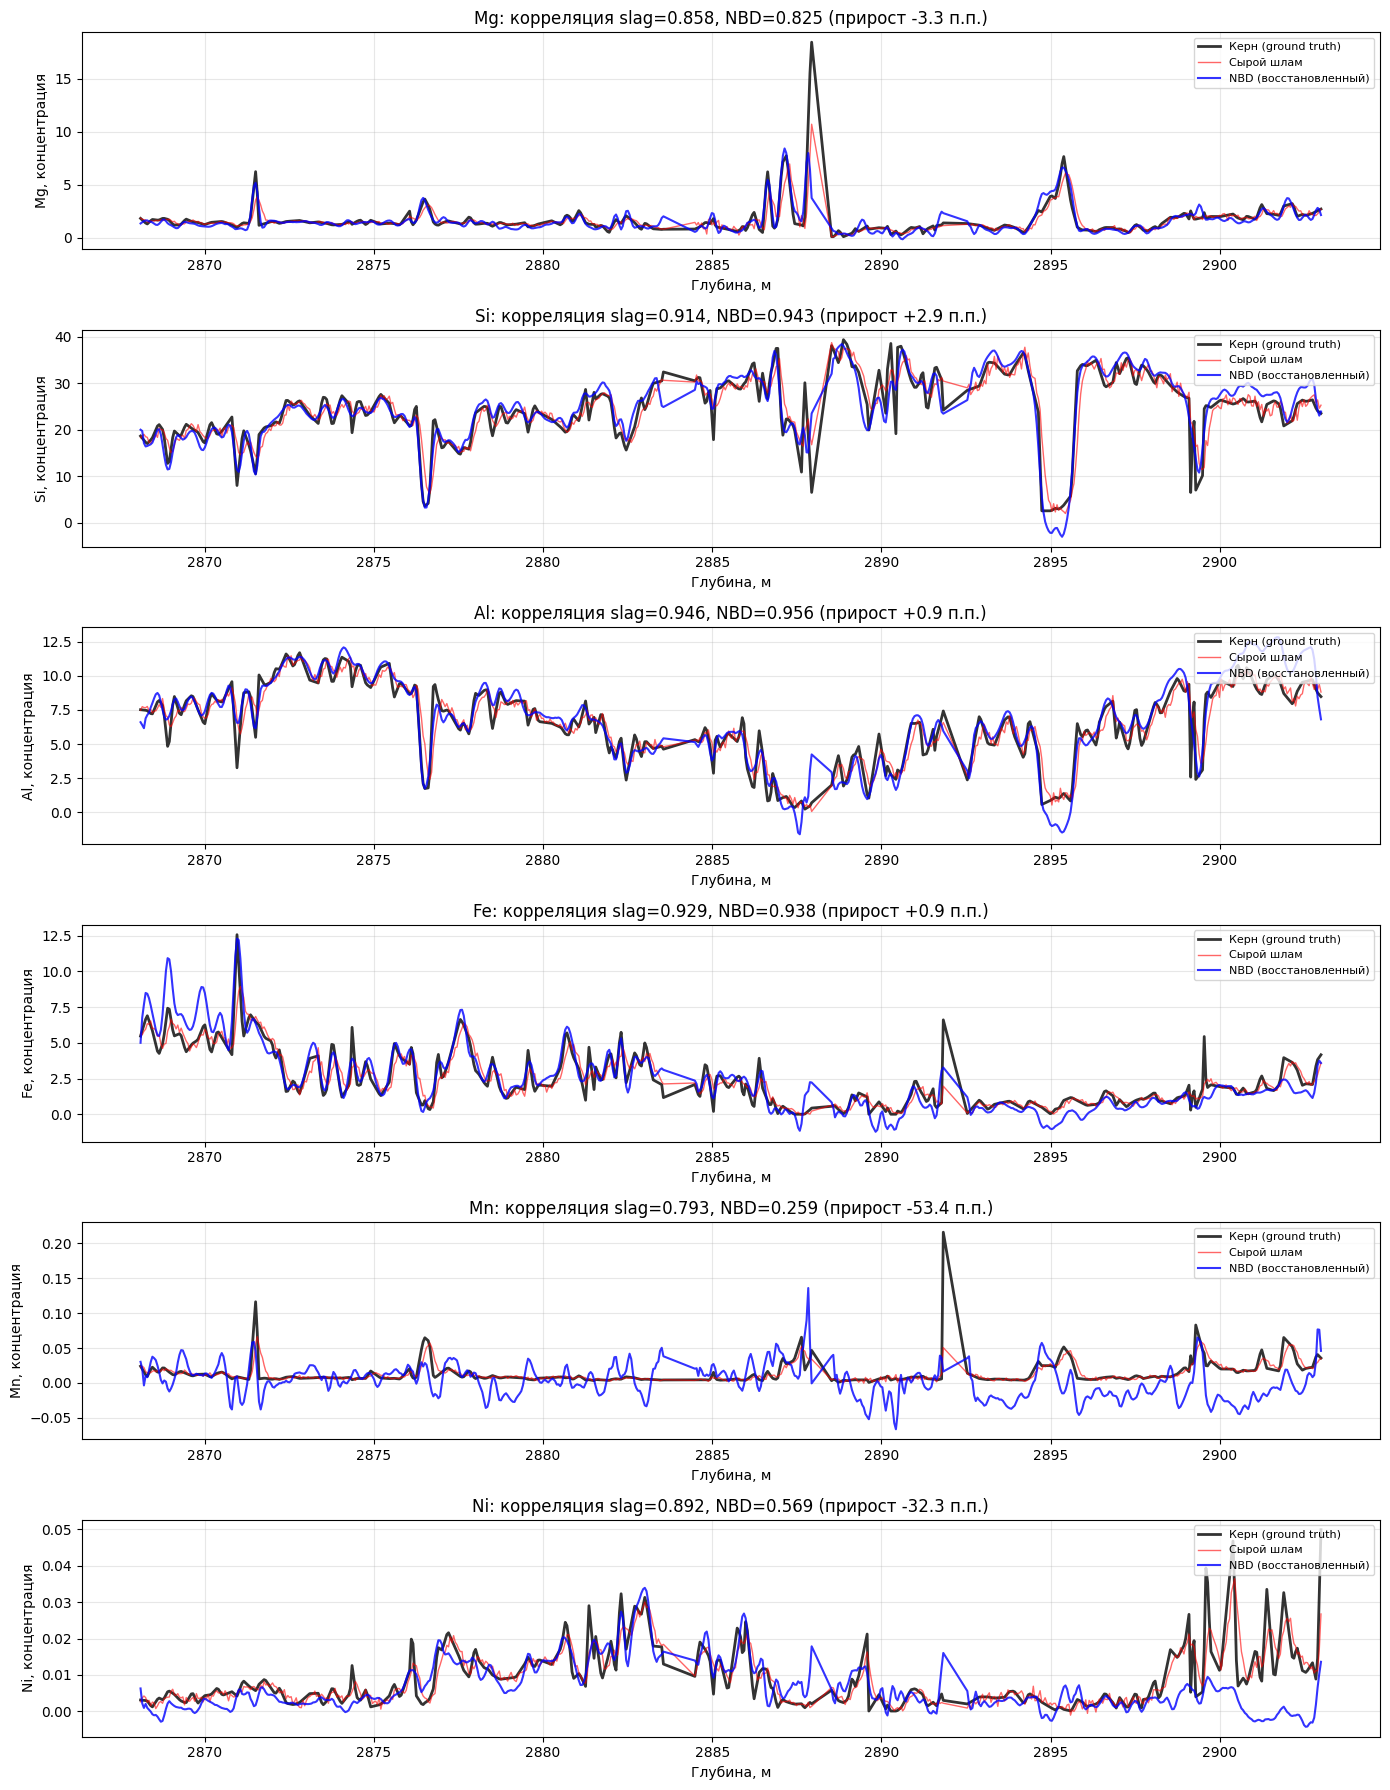


СВОДНАЯ ТАБЛИЦА КОРРЕЛЯЦИЙ (все элементы)
Element  corr(slag, kern)  corr(nbd, kern)  Improvement
     Mg          0.857755         0.824929    -0.032826
     Si          0.914037         0.942989     0.028952
     Al          0.946087         0.955543     0.009456
     Fe          0.929335         0.938163     0.008828
     Mn          0.793366         0.259177    -0.534189
     Ni          0.891566         0.568592    -0.322974


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# NBD-данные (содержат kern, slag, nbd)
df_nbd = pd.read_csv("Result/NBD_cleaned/synthetic_slag_w0.5_s0.1_nbd.csv")

# Элементы для визуализации (ключевые)
elements_to_plot = ['Mg', 'Si', 'Al', 'Fe', 'Mn', 'Ni']

# Выбираем одну скважину (например, C3 — test-скважина)
well = 'C3'
df_well = df_nbd[df_nbd['Well'] == well].sort_values('Depth').reset_index(drop=True)

# Убираем маркеры разрывов (где kern = NaN)
df_well = df_well.dropna(subset=[f'{el}_kern' for el in elements_to_plot]).reset_index(drop=True)

print(f"Скважина {well}: {len(df_well)} проб")

fig, axes = plt.subplots(len(elements_to_plot), 1, figsize=(14, 3 * len(elements_to_plot)))

for i, el in enumerate(elements_to_plot):
    ax = axes[i]
    
    # Данные
    depths = df_well['Depth'].values
    kern = df_well[f'{el}_kern'].values
    slag = df_well[f'{el}_slag'].values
    nbd = df_well[f'{el}_nbd'].values
    
    # Корреляции
    corr_slag, _ = pearsonr(slag, kern)
    corr_nbd, _ = pearsonr(nbd, kern)
    improvement = corr_nbd - corr_slag
    
    # График
    ax.plot(depths, kern, 'k-', label='Керн (ground truth)', linewidth=2, alpha=0.8)
    ax.plot(depths, slag, 'r-', label='Сырой шлам', linewidth=1, alpha=0.6)
    ax.plot(depths, nbd, 'b-', label='NBD (восстановленный)', linewidth=1.5, alpha=0.8)
    
    ax.set_xlabel('Глубина, м')
    ax.set_ylabel(f'{el}, концентрация')
    ax.set_title(f'{el}: корреляция slag={corr_slag:.3f}, NBD={corr_nbd:.3f} '
                 f'(прирост {improvement*100:+.1f} п.п.)')
    ax.legend(loc='upper right', fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('Result/NBD_vs_slag_vs_kern.png', dpi=150, bbox_inches='tight')
plt.show()


print("СВОДНАЯ ТАБЛИЦА КОРРЕЛЯЦИЙ (все элементы)")

corr_results = []
for el in elements_to_plot:
    kern = df_well[f'{el}_kern'].values
    slag = df_well[f'{el}_slag'].values
    nbd = df_well[f'{el}_nbd'].values
    
    corr_slag, _ = pearsonr(slag, kern)
    corr_nbd, _ = pearsonr(nbd, kern)
    
    corr_results.append({
        'Element': el,
        'corr(slag, kern)': corr_slag,
        'corr(nbd, kern)': corr_nbd,
        'Improvement': corr_nbd - corr_slag,
    })

df_corr = pd.DataFrame(corr_results)
print(df_corr.to_string(index=False))
df_corr.to_csv('Result/NBD_correlations_summary.csv', index=False)

In [4]:
for well in ['C2', 'C7']:
    df_well = df_nbd[df_nbd['Well'] == well].sort_values('Depth').reset_index(drop=True)
    df_well = df_well.dropna(subset=[f'{el}_kern' for el in elements_to_plot]).reset_index(drop=True)
    
    print(f"\nСкважина {well}:")
    for el in ['Mg', 'Mn', 'Ni']:
        kern = df_well[f'{el}_kern'].values
        slag = df_well[f'{el}_slag'].values
        nbd = df_well[f'{el}_nbd'].values
        corr_slag, _ = pearsonr(slag, kern)
        corr_nbd, _ = pearsonr(nbd, kern)
        print(f"  {el}: slag={corr_slag:.3f}, nbd={corr_nbd:.3f} (прирост {corr_nbd-corr_slag:+.3f})")


Скважина C2:
  Mg: slag=0.776, nbd=0.950 (прирост +0.174)
  Mn: slag=0.792, nbd=0.788 (прирост -0.004)
  Ni: slag=0.776, nbd=0.903 (прирост +0.127)

Скважина C7:
  Mg: slag=0.703, nbd=0.837 (прирост +0.134)
  Mn: slag=0.820, nbd=0.559 (прирост -0.261)
  Ni: slag=0.859, nbd=0.717 (прирост -0.142)


In [5]:
for well in ['A1', 'A3', 'C1']:  # train-скважины
    df_well = df_nbd[df_nbd['Well'] == well].sort_values('Depth').reset_index(drop=True)
    df_well = df_well.dropna(subset=[f'{el}_kern' for el in elements_to_plot]).reset_index(drop=True)
    
    print(f"\nСкважина {well} (train):")
    for el in ['Mg', 'Mn', 'Ni']:
        kern = df_well[f'{el}_kern'].values
        slag = df_well[f'{el}_slag'].values
        nbd = df_well[f'{el}_nbd'].values
        corr_slag, _ = pearsonr(slag, kern)
        corr_nbd, _ = pearsonr(nbd, kern)
        print(f"  {el}: slag={corr_slag:.3f}, nbd={corr_nbd:.3f} (прирост {corr_nbd-corr_slag:+.3f})")


Скважина A1 (train):
  Mg: slag=0.738, nbd=0.899 (прирост +0.161)
  Mn: slag=0.770, nbd=0.617 (прирост -0.153)
  Ni: slag=0.837, nbd=0.908 (прирост +0.071)

Скважина A3 (train):
  Mg: slag=0.822, nbd=0.948 (прирост +0.126)
  Mn: slag=0.824, nbd=0.686 (прирост -0.137)
  Ni: slag=0.874, nbd=0.934 (прирост +0.059)

Скважина C1 (train):
  Mg: slag=0.802, nbd=0.889 (прирост +0.087)
  Mn: slag=0.904, nbd=0.703 (прирост -0.201)
  Ni: slag=0.881, nbd=0.768 (прирост -0.113)


In [6]:
elements = ['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe',
            'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo']

train_wells = ['A1', 'A3', 'A4', 'B1', 'C1', 'C4', 'C5', 'C6', 'D1']
test_wells = ['C2', 'C3', 'C7']

print(f"{'Element':<8} {'Train (mean)':<15} {'Test (mean)':<15} {'Improvement':<12}")
print("-" * 55)

for el in elements:
    train_improvements = []
    test_improvements = []
    
    for well in train_wells + test_wells:
        df_well = df_nbd[df_nbd['Well'] == well].sort_values('Depth').reset_index(drop=True)
        df_well = df_well.dropna(subset=[f'{el}_kern']).reset_index(drop=True)
        
        if len(df_well) < 10:
            continue
        
        kern = df_well[f'{el}_kern'].values
        slag = df_well[f'{el}_slag'].values
        nbd = df_well[f'{el}_nbd'].values
        
        corr_slag, _ = pearsonr(slag, kern)
        corr_nbd, _ = pearsonr(nbd, kern)
        improvement = corr_nbd - corr_slag
        
        if well in train_wells:
            train_improvements.append(improvement)
        else:
            test_improvements.append(improvement)
    
    train_mean = np.mean(train_improvements) if train_improvements else np.nan
    test_mean = np.mean(test_improvements) if test_improvements else np.nan
    
    print(f"{el:<8} {train_mean:+.3f}          {test_mean:+.3f}          {test_mean - train_mean:+.3f}")

Element  Train (mean)    Test (mean)     Improvement 
-------------------------------------------------------
Mg       +0.152          +0.092          -0.061
Al       +0.038          +0.020          -0.018
Si       +0.067          +0.048          -0.019
P        +0.149          +0.085          -0.064
S        +0.060          +0.016          -0.043
K        +0.042          +0.014          -0.028
Ca       +0.107          +0.068          -0.039
Ti       +0.035          +0.027          -0.008
Mn       -0.125          -0.266          -0.141
Fe       +0.060          +0.011          -0.049
Ni       -0.004          -0.113          -0.109
Cu       +0.030          -0.014          -0.044
Zn       +0.108          +0.073          -0.035
Se       +0.009          +0.020          +0.011
Rb       +0.040          -0.135          -0.174
Sr       +0.148          -0.055          -0.203
Zr       +0.021          -0.139          -0.160
Mo       +0.025          -0.026          -0.050
